# Winners-loosers 

In [1]:
import pandas as pd
import numpy as np
import scipy as sp

from os import listdir
from collections import OrderedDict

import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import matplotlib as mpl

In [2]:
import sys
sys.path.append("../functions/")
import abundance_sim_analysis

In [3]:
%load_ext autoreload
%autoreload 2

**Load and process data**

In [4]:
abundances_df = pd.read_csv(f"../output/Guillen2021/results_steadiercom/results_growth/ecoli_mutants_abundance.tsv",sep="\t")

abundances_df.reset_index(drop=True)

,sample,member,relative_abundance,community,medium
0,0,mutant_panZ,0.007743,ecoli_auxotrophs,M9
1,0,mutant_icd,0.992257,ecoli_auxotrophs,M9
2,1,mutant_panD,0.000269,ecoli_auxotrophs,M9
3,1,mutant_bioF,0.999731,ecoli_auxotrophs,M9
4,2,mutant_panZ,0.000223,ecoli_auxotrophs,M9
...,...,...,...,...,...
9270,3997,mutant_bioH,0.925844,ecoli_auxotrophs,M9
9271,3998,mutant_panD,0.000293,ecoli_auxotrophs,M9
9272,3998,mutant_bioF,0.999707,ecoli_auxotrophs,M9
9273,3999,mutant_cysW,0.000227,ecoli_auxotrophs,M9


**Filter out 1-member communities**

In [5]:
count_members_sample = abundances_df[["sample","community"]].value_counts()
count_above_1 = count_members_sample[count_members_sample>1].index


abundance_filtered = abundances_df[abundances_df[["sample", "community"]].apply(tuple, axis=1).isin(count_above_1)
].copy()

**Do a count of how often members are predicted to grow together**

In [6]:
abundance_filtered.value_counts("member")

member
mutant_cysW    1481
mutant_icd     1434
mutant_panD    1424
mutant_panZ    1277
mutant_bioC    1239
mutant_bioF    1238
mutant_bioH    1182
Name: count, dtype: int64

### Co-growth count - in how many samples are two members predicted to grow together?  (NB: member1=member2 is set to 0)

[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.


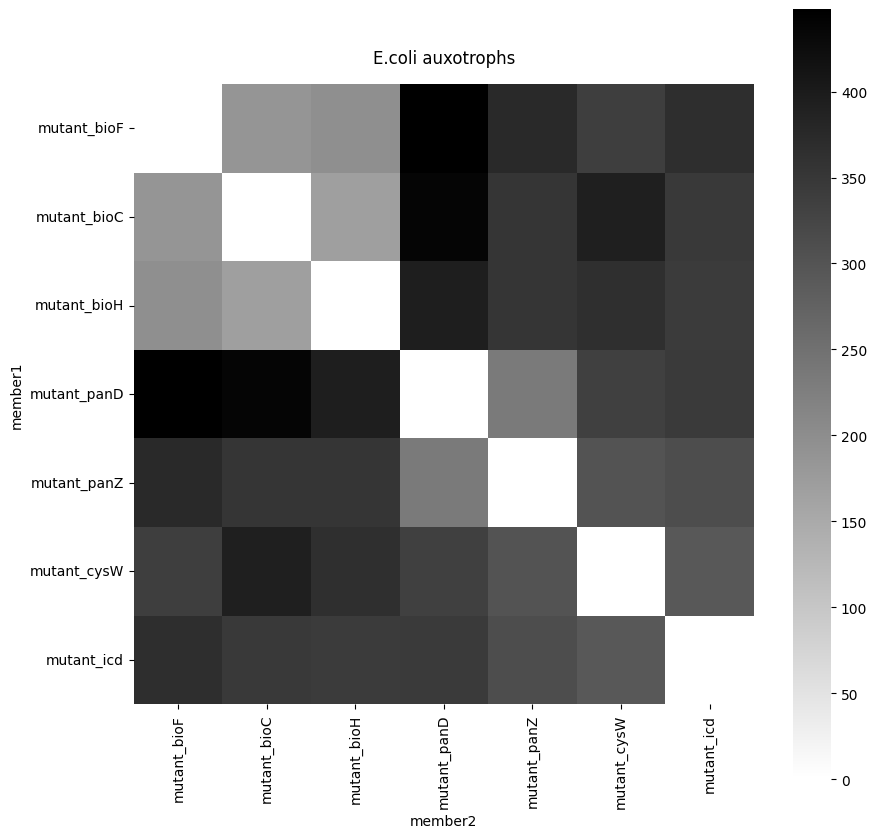

In [7]:
abundance_sim_analysis.plot_co_growth_count_guillen(abundance_filtered)

### Winners and loosers

#### Full community

In [8]:
co_growth_count_none,member_abund_df_none = abundance_sim_analysis.make_co_growth_count_matrix(abundance_filtered,"ecoli_auxotrophs")

[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.


<Axes: ylabel='member'>

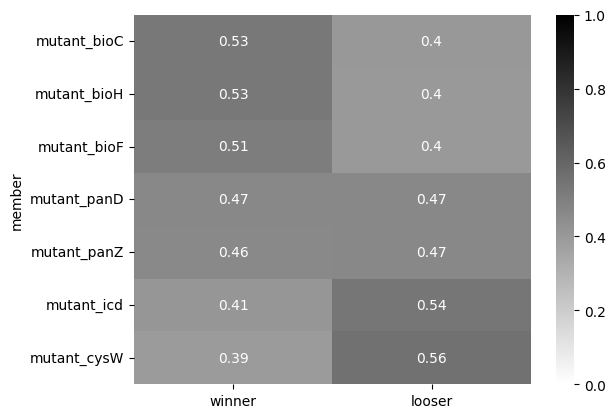

In [9]:
abundance_no_zeros = member_abund_df_none[member_abund_df_none>1e-6]
total_counts = abundance_no_zeros.count()

winner = abundance_no_zeros.eq(abundance_no_zeros.max(axis=1),axis=0).sum().sort_values()
winner = (winner/total_counts).sort_values()
winner.name="winner"

looser = abundance_no_zeros.eq(abundance_no_zeros.min(axis=1),axis=0).sum().sort_values()
looser = (looser/total_counts).sort_values()
looser.name="looser"

winner_looser = pd.concat([winner,looser],axis=1)
winner_looser = winner_looser.sort_values(by="winner",ascending=False)
sns.heatmap(winner_looser,cmap="binary",vmin=0,vmax=1,annot=True)

### Comparing relative abundance of losers vs winners

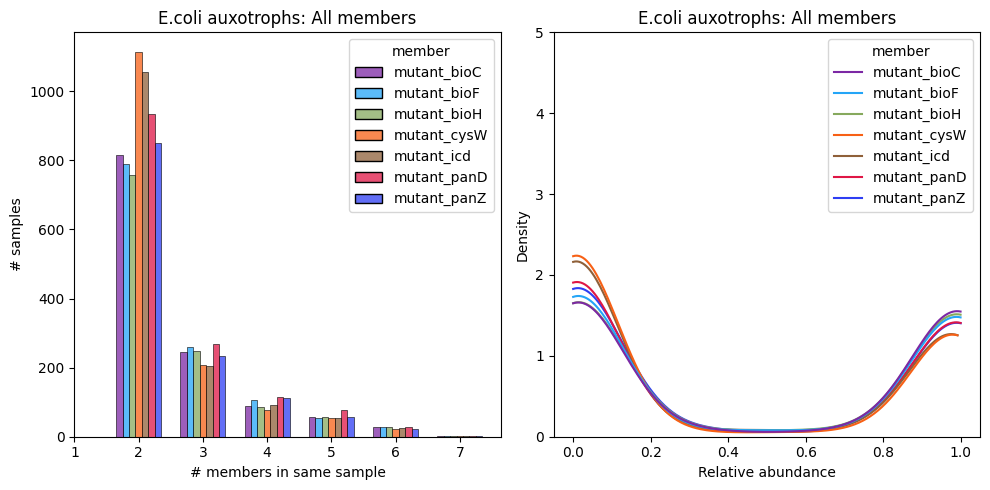

In [11]:
abundance_sim_analysis.plot_co_ind_growers_guillen(abundances_df)